In [5]:
import sys
import pandas as pd
import numpy as np
import os
import importlib
from src.eval_utils import full_evaluation
from src.modeltrainer import *
import matplotlib.pyplot as plt
import glob

# Reimporter les modules pour refléter les modifications
importlib.reload(sys.modules['src.eval_utils'])
importlib.reload(sys.modules['src.modeltrainer'])

sys.path.insert(0, './src')

In [3]:
# =============================================================================
# CELLULE 1 : IMPORT DES DONNÉES
# =============================================================================


# Configuration
DATA_PATH = 'data/processed_data_imputed.xlsx'
COLS_TO_DROP = ['patient_ids', 'feat_40', 'feat_82']

# Chargement des données
print("📂 Chargement des données...")

train_data = pd.read_excel(DATA_PATH, sheet_name='train')
cal_data = pd.read_excel(DATA_PATH, sheet_name='calibration')
test_data = pd.read_excel(DATA_PATH, sheet_name='test')

# Séparation features / target
X_train = train_data.iloc[:, :-1].drop(columns=COLS_TO_DROP, errors='ignore')
y_train = train_data.iloc[:, -1]

X_cal = cal_data.iloc[:, :-1].drop(columns=COLS_TO_DROP, errors='ignore')
y_cal = cal_data.iloc[:, -1]

X_test = test_data.iloc[:, :-1].drop(columns=COLS_TO_DROP, errors='ignore')
y_test = test_data.iloc[:, -1]

print(f"✓ Données chargées:")
print(f"   - Train: {X_train.shape[0]} lignes, {X_train.shape[1]} features")
print(f"   - Calibration: {X_cal.shape[0]} lignes")
print(f"   - Test: {X_test.shape[0]} lignes")
print(f"   - Target distribution (train): {y_train.value_counts().to_dict()}")

📂 Chargement des données...
✓ Données chargées:
   - Train: 83555 lignes, 81 features
   - Calibration: 28381 lignes
   - Test: 28465 lignes
   - Target distribution (train): {0: 46672, 1: 36883}


In [6]:
# =============================================================================
# CELLULE 2 : CHARGEMENT OU ENTRAÎNEMENT DU MODÈLE RandomForest
# =============================================================================


# Configuration
MODEL_DIR = 'models'
MODEL_TYPE = 'RandomForest'  # 'LogisticRegression', 'RandomForest', 'XGBoost'



# Initialiser le trainer
trainer = ModelML(
    x_train=X_train,
    x_test=X_test,
    y_train=y_train,
    y_test=y_test
)

# Chercher un modèle existant
existing_model = find_existing_model(MODEL_DIR, MODEL_TYPE)

if existing_model:
    print(f"📦 Modèle existant trouvé: {existing_model}")
    trainer.load_model(existing_model)
else:
    print(f"🔄 Aucun modèle {MODEL_TYPE} trouvé. Entraînement en cours...")
    
    trainer.tune_random_forest(
        param_grid={
            'n_estimators': [50, 100, 200],
            'max_depth': [3, 5, 10, None],
            'min_samples_leaf': [1, 2],
            'max_features': ['sqrt']
        },
        method='random',
        n_iter=20,
        cv=5,
        scoring='roc_auc'
    )
    
    trainer.save_model()
    print(f"✓ Modèle entraîné et sauvegardé")

print(f"\n📊 Modèle actif: {trainer.model_name}")
print(f"   Paramètres: {trainer.best_params}")

🔄 Aucun modèle RandomForest trouvé. Entraînement en cours...

🔍 Recherche d'hyperparamètres (RANDOM)
   Modèle: random_forest_tuned
   Scoring: roc_auc
   CV folds:  5
   Paramètres testés: ['n_estimators', 'max_depth', 'min_samples_leaf', 'max_features']
Fitting 5 folds for each of 20 candidates, totalling 100 fits


/home/mouad-sehli/datascience/lib/python3.12/site-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(



✓ Meilleurs paramètres trouvés:
   - n_estimators:  200
   - min_samples_leaf:  1
   - max_features:  sqrt
   - max_depth:  None
   - Best CV Score (roc_auc): 0.9572

📊 Résultats:
   - Train Accuracy: 1.0000
   - Test Accuracy:  0.7096
✓ Modèle sauvegardé: models/random_forest_tuned.pkl
✓ Paramètres sauvegardés: models/random_forest_tuned_params.json
✓ Modèle entraîné et sauvegardé

📊 Modèle actif: random_forest_tuned
   Paramètres: {'n_estimators': 200, 'min_samples_leaf': 1, 'max_features': 'sqrt', 'max_depth': None}



📊 ÉVALUATION SUR LE TRAIN SET

🔍 ÉVALUATION COMPLÈTE:  random_forest_tuned_train
📊 MÉTRIQUES D'ÉVALUATION

🎯 Métriques de Classification:
----------------------------------------
   Accuracy                 : 1.0000
   Balanced_Accuracy        : 1.0000
   Precision                : 1.0000
   Recall_Sensitivity       : 1.0000
   Specificity              : 1.0000
   F1_Score                 : 1.0000
   Matthews_Corr_Coef       : 1.0000
   Cohen_Kappa              : 1.0000

📈 Métriques Probabilistes:
----------------------------------------
   ROC_AUC                  : 1.0000
   PR_AUC                   : 1.0000
   Brier_Score              : 0.0128
   Log_Loss                 : 0.0971

📋 RAPPORT DE CLASSIFICATION
              precision    recall  f1-score   support

    Classe 0       1.00      1.00      1.00     46672
    Classe 1       1.00      1.00      1.00     36883

    accuracy                           1.00     83555
   macro avg       1.00      1.00      1.00     83555
weight

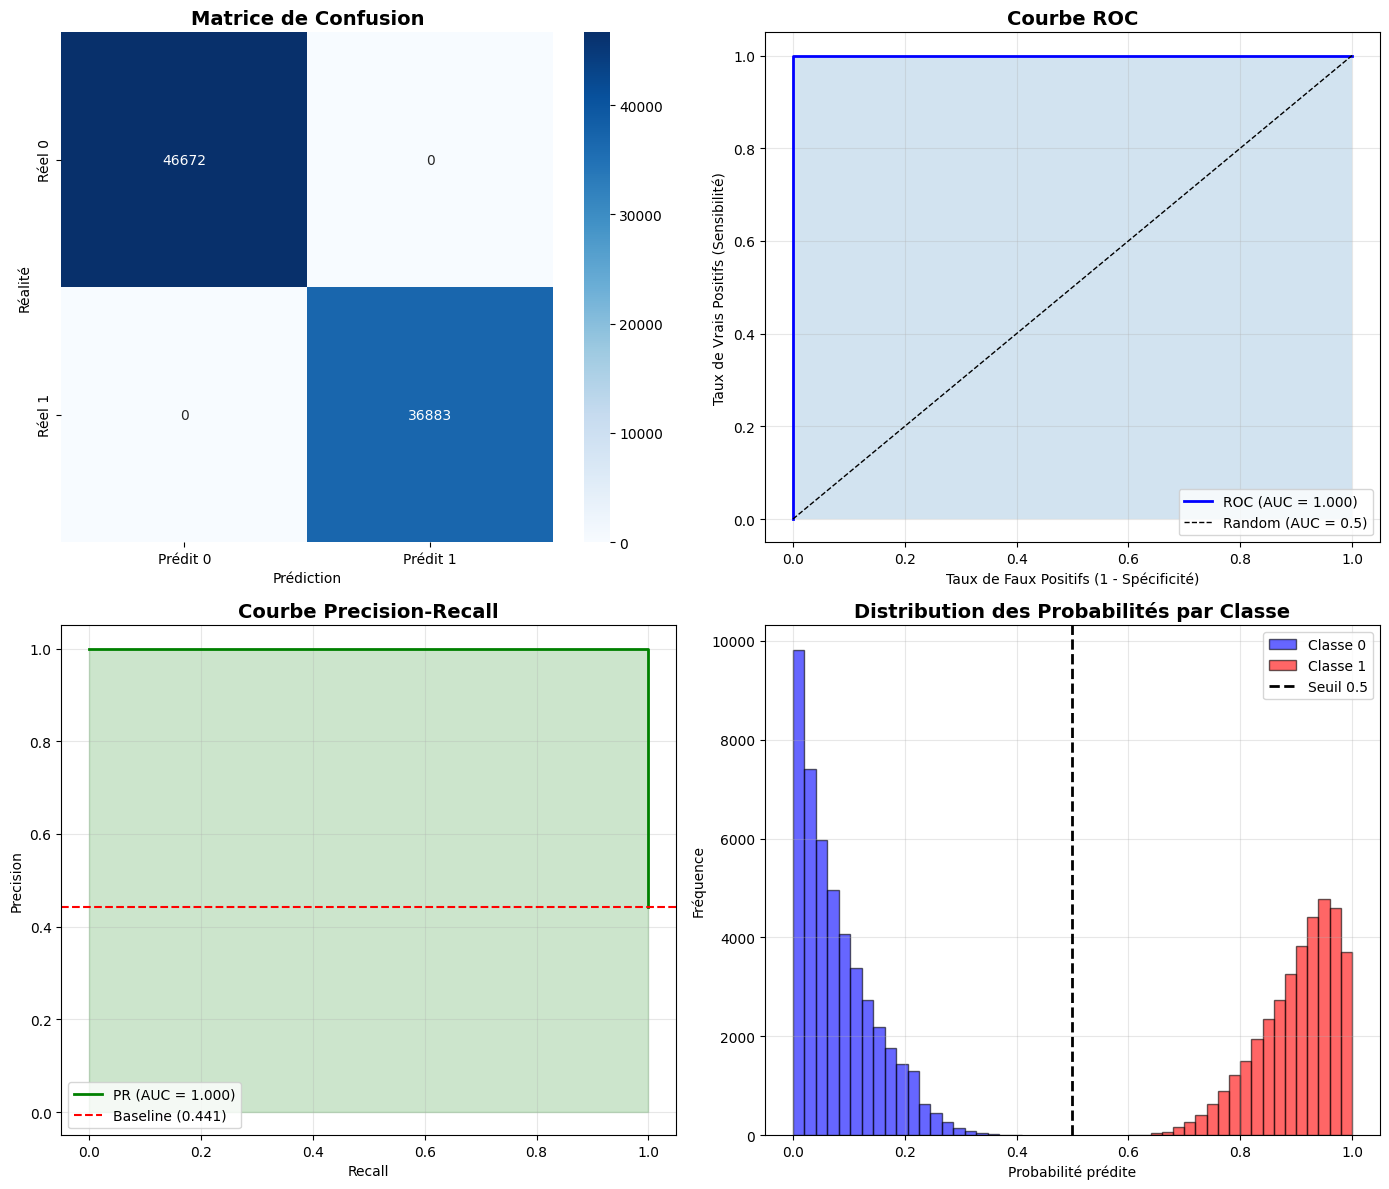

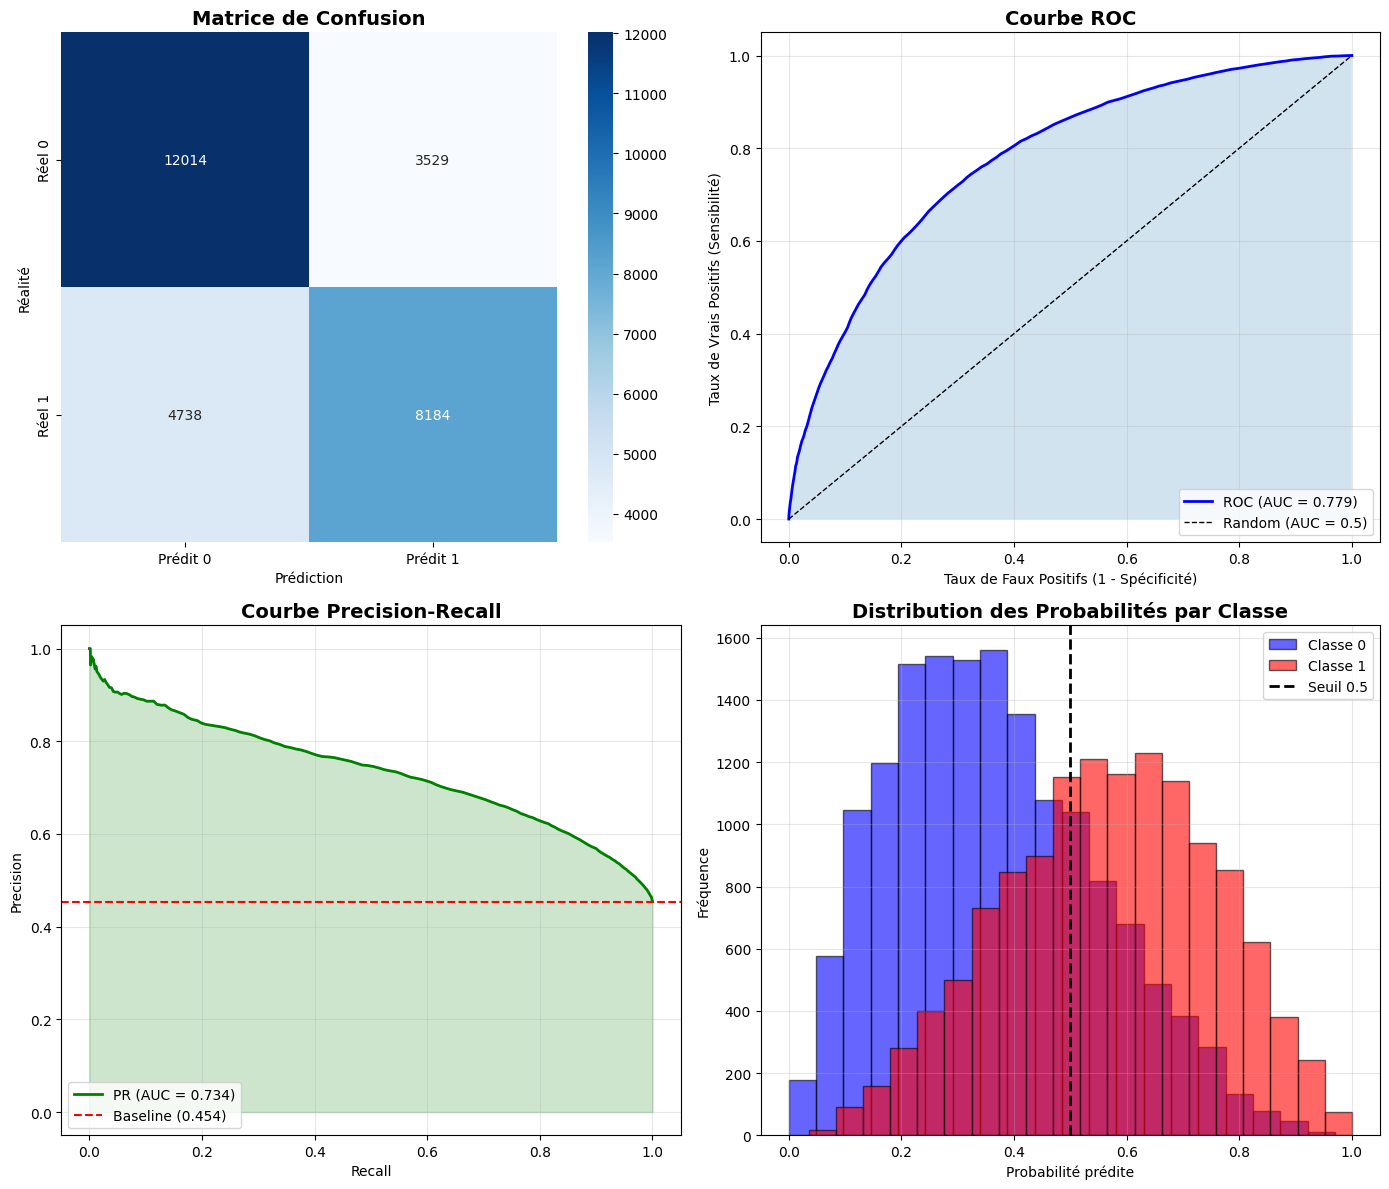


📈 COMPARAISON TRAIN vs TEST
Métrique                         Train         Test         Diff
----------------------------------------------------------------------
Accuracy                        1.0000       0.7096      +0.2904
Balanced_Accuracy               1.0000       0.7031      +0.2969
Precision                       1.0000       0.6987      +0.3013
Recall_Sensitivity              1.0000       0.6333      +0.3667
Specificity                     1.0000       0.7730      +0.2270
F1_Score                        1.0000       0.6644      +0.3356
Matthews_Corr_Coef              1.0000       0.4111      +0.5889
Cohen_Kappa                     1.0000       0.4095      +0.5905
ROC_AUC                         1.0000       0.7790      +0.2210
PR_AUC                          1.0000       0.7340      +0.2660
Brier_Score                     0.0128       0.1915      -0.1787
Log_Loss                        0.0971       0.5648      -0.4677


In [7]:
# =============================================================================
# CELLULE 3 : ÉVALUATION COMPLÈTE SUR LE TRAIN ET TEST SET
# =============================================================================

# --- Évaluation sur le TRAIN SET ---
print("\n" + "="*70)
print("📊 ÉVALUATION SUR LE TRAIN SET")
print("="*70)

y_pred_train = trainer.predict(X_train)
y_proba_train = trainer.predict_proba(X_train)[:, 1]

metrics_train = full_evaluation(
    y_true=y_train,
    y_pred=y_pred_train,
    y_proba=y_proba_train,
    model_name=f"{trainer.model_name}_train",
    save_dir='results'
)

# --- Évaluation sur le TEST SET ---
print("\n" + "="*70)
print("📊 ÉVALUATION SUR LE TEST SET")
print("="*70)

y_pred_test = trainer.predict(X_test)
y_proba_test = trainer.predict_proba(X_test)[:, 1]

metrics_test = full_evaluation(
    y_true=y_test,
    y_pred=y_pred_test,
    y_proba=y_proba_test,
    model_name=f"{trainer.model_name}_test",
    save_dir='results'
)

# Afficher les plots
plt.show()

# Résumé comparatif
print("\n" + "="*70)
print("📈 COMPARAISON TRAIN vs TEST")
print("="*70)
print(f"{'Métrique':<25} {'Train':>12} {'Test':>12} {'Diff':>12}")
print("-"*70)
for key in metrics_train.keys():
    train_val = metrics_train[key]
    test_val = metrics_test[key]
    diff = train_val - test_val
    print(f"{key:<25} {train_val:>12.4f} {test_val:>12.4f} {diff:>+12.4f}")